In [ ]:
from pathlib import Path
import copy
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import albumentations as A
from albumentations.pytorch import ToTensorV2

PROJECT_ROOT = Path("../")
sys.path.insert(0, str((PROJECT_ROOT / "src").resolve()))

from data.datasets import decode_ground_truth
from data.transforms import (
    build_labeled_shared_geometry,
    build_labeled_strong_transform,
    build_labeled_weak_transform,
    build_unlabeled_shared_geometry,
    build_unlabeled_strong_transform,
    build_unlabeled_weak_transform,
)

In [ ]:
SEED = 42
IMAGE_SIZE = (256, 256)
FORCE_AUGMENTATIONS = True
IMAGE_DIR = PROJECT_ROOT / "data/data/train"
MASK_DIR = PROJECT_ROOT / "data/data/gt"
IMAGE_PATH = IMAGE_DIR / "01e80947f9c02314fc58bdb26679bff5.jpeg"
GROUND_TRUTH_PATH = MASK_DIR / IMAGE_PATH.name
UNLABELED_IMAGE_PATH = IMAGE_PATH
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
PALETTE = np.array([[0, 0, 0], [0, 255, 0], [255, 0, 0]], dtype=np.uint8)
print(
    "Augmentation mode:",
    "forced demonstration" if FORCE_AUGMENTATIONS else "training probabilities",
)

Augmentation mode: forced demonstration


In [ ]:
def show_image(image, label):
    print(label)
    fig = plt.figure(figsize=(4.5, 4.5), dpi=100)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(image, interpolation="nearest")
    ax.axis("off")
    plt.show()
    plt.close(fig)


def as_numpy(value):
    return value.detach().cpu().numpy() if torch.is_tensor(value) else np.asarray(value)


def show_state(state, label):
    image = as_numpy(state["image"])
    if torch.is_tensor(state["image"]):
        image = image.transpose(1, 2, 0)
    preview = np.clip(image * STD + MEAN, 0, 1) if state.get("normalized") else image
    suffix = " (inverse normalized preview)" if state.get("normalized") else ""
    show_image(preview, label + " - Image" + suffix)
    if "mask" in state:
        mask = as_numpy(state["mask"])
        show_image(PALETTE[mask.astype(np.int64)], label + " - Ground truth")
        print(
            "Mask:",
            tuple(state["mask"].shape),
            state["mask"].dtype,
            "classes:",
            np.unique(mask).tolist(),
        )
    value = state["image"]
    print(
        "Image:",
        tuple(value.shape),
        value.dtype,
        "range:",
        (float(image.min()), float(image.max())),
    )


def read_image(path, label):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    state = {"image": cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "normalized": False}
    show_state(state, label)
    return state


def add_ground_truth(previous, path, label):
    raw = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if raw is None:
        raise FileNotFoundError(path)
    if raw.ndim == 3:
        raw = cv2.cvtColor(
            raw, cv2.COLOR_BGRA2RGB if raw.shape[-1] == 4 else cv2.COLOR_BGR2RGB
        )
    mask = decode_ground_truth(raw)
    if mask.shape != previous["image"].shape[:2]:
        raise ValueError("Image and ground truth must have matching dimensions.")
    state = {"image": previous["image"].copy(), "mask": mask, "normalized": False}
    show_state(state, label)
    return state


def describe_transform(record):
    name = record["__class_fullname__"].split(".")[-1]
    if not record.get("applied"):
        return name + " [skipped]"
    children = record.get("transforms")
    if children is not None:
        return (
            name
            + " -> "
            + ", ".join(describe_transform(c) for c in children if c.get("applied"))
        )
    return name + " [applied]"


def next_step(previous, transform, label, seed):
    operation = copy.deepcopy(transform)
    if FORCE_AUGMENTATIONS:
        operation.p = 1.0
    pipeline = A.ReplayCompose([operation])
    pipeline.set_random_seed(seed)
    inputs = {"image": previous["image"].copy()}
    if "mask" in previous:
        inputs["mask"] = previous["mask"].copy()
    result = pipeline(**inputs)
    state = {
        "image": result["image"],
        "normalized": previous.get("normalized", False)
        or isinstance(operation, A.Normalize),
    }
    if "mask" in previous:
        state["mask"] = (
            result["mask"].long() if torch.is_tensor(result["mask"]) else result["mask"]
        )
    print(describe_transform(result["replay"]["transforms"][0]))
    show_state(state, label)
    return state

# Supervised

In [ ]:
supervised_steps = [
    A.Resize(*IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.0625,
        scale_limit=0.15,
        rotate_limit=45,
        border_mode=cv2.BORDER_CONSTANT,
        p=0.5,
    ),
    A.OneOf(
        [
            A.ElasticTransform(alpha=120, sigma=6, p=0.5),
            A.GridDistortion(p=0.5),
            A.OpticalDistortion(distort_limit=1, p=0.5),
        ],
        p=0.4,
    ),
    A.OneOf(
        [
            A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
            A.HueSaturationValue(
                hue_shift_limit=10, sat_shift_limit=15, val_shift_limit=10, p=0.5
            ),
        ],
        p=0.3,
    ),
    A.OneOf(
        [
            A.GaussNoise(std_range=(np.sqrt(10) / 255, np.sqrt(30) / 255), p=0.5),
            A.GaussianBlur(blur_limit=(3, 5), p=0.5),
        ],
        p=0.2,
    ),
    A.Normalize(mean=tuple(MEAN), std=tuple(STD)),
    ToTensorV2(),
]

B:\_projects\poply-image-segmentation\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Supervised - 1. Read image and convert BGR to RGB - Image


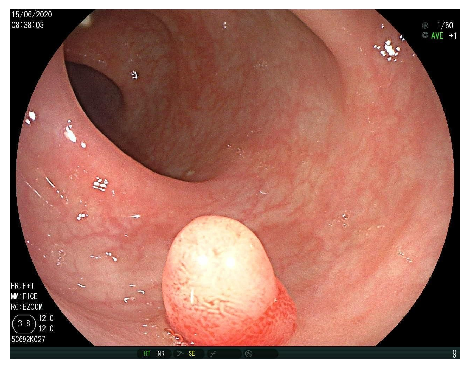

Image: (995, 1280, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_image = read_image(
    IMAGE_PATH, "Supervised - 1. Read image and convert BGR to RGB"
)

Supervised - 2. Read and decode ground truth - Image


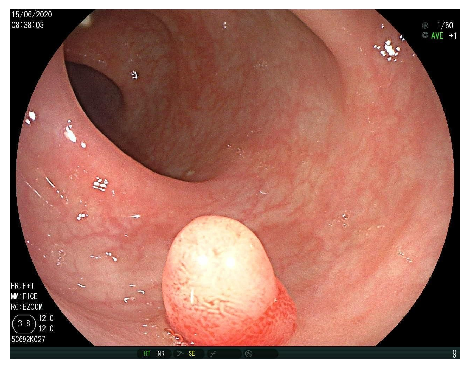

Supervised - 2. Read and decode ground truth - Ground truth


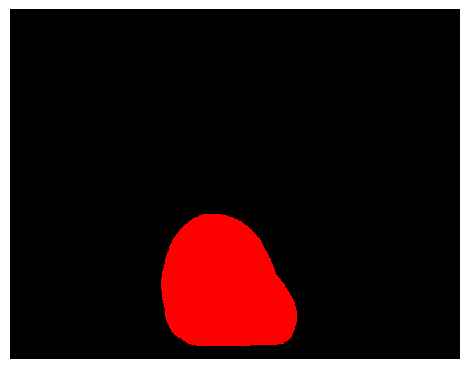

Mask: (995, 1280) uint8 classes: [0, 2]
Image: (995, 1280, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_input = add_ground_truth(
    supervised_image, GROUND_TRUTH_PATH, "Supervised - 2. Read and decode ground truth"
)

Resize [applied]
Supervised - 3. Resize to 256 x 256 - Image


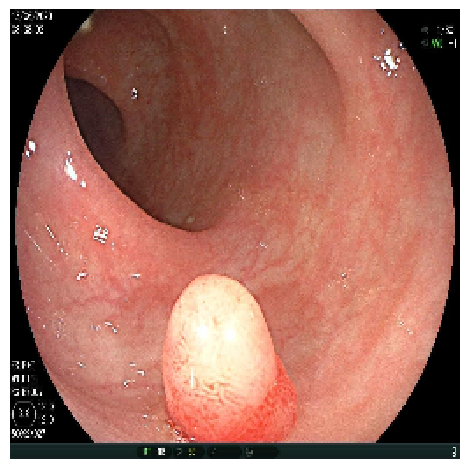

Supervised - 3. Resize to 256 x 256 - Ground truth


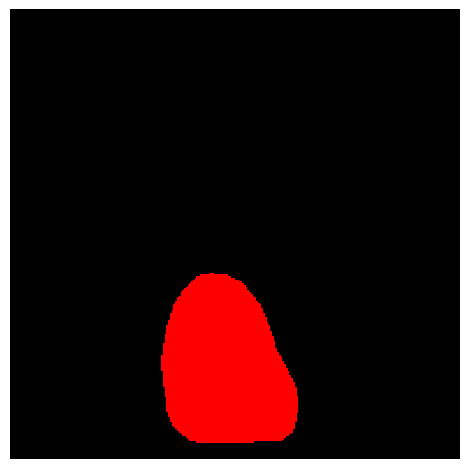

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_1 = next_step(
    supervised_input,
    supervised_steps[0],
    "Supervised - 3. Resize to 256 x 256",
    SEED + 0,
)

HorizontalFlip [applied]
Supervised - 4. Horizontal flip - Image


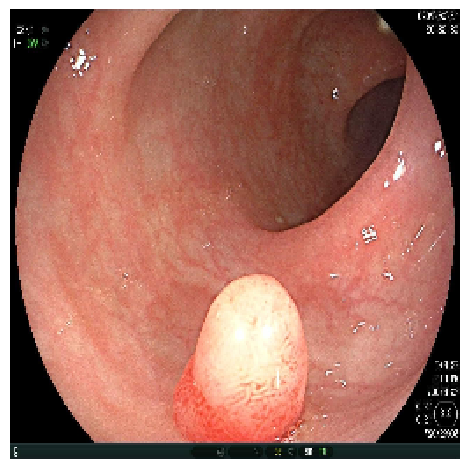

Supervised - 4. Horizontal flip - Ground truth


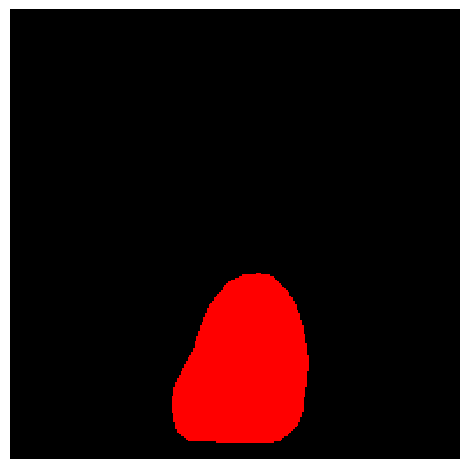

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_2 = next_step(
    supervised_1, supervised_steps[1], "Supervised - 4. Horizontal flip", SEED + 1
)

VerticalFlip [applied]
Supervised - 5. Vertical flip - Image


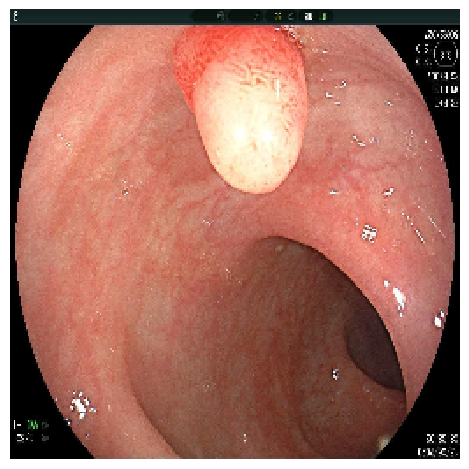

Supervised - 5. Vertical flip - Ground truth


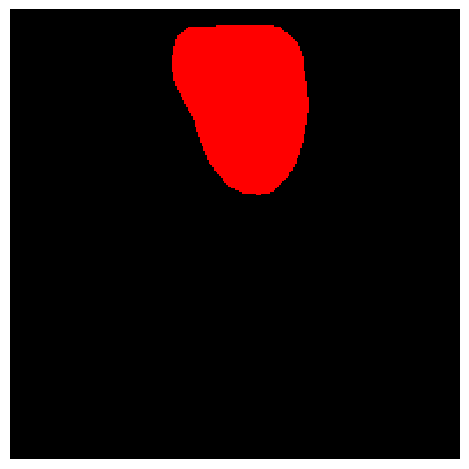

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_3 = next_step(
    supervised_2, supervised_steps[2], "Supervised - 5. Vertical flip", SEED + 2
)

RandomRotate90 [applied]
Supervised - 6. Random rotate 90 degrees - Image


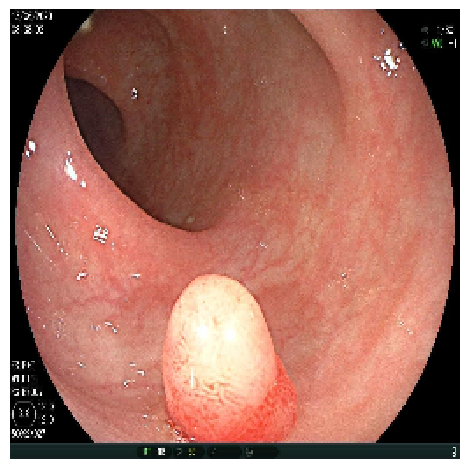

Supervised - 6. Random rotate 90 degrees - Ground truth


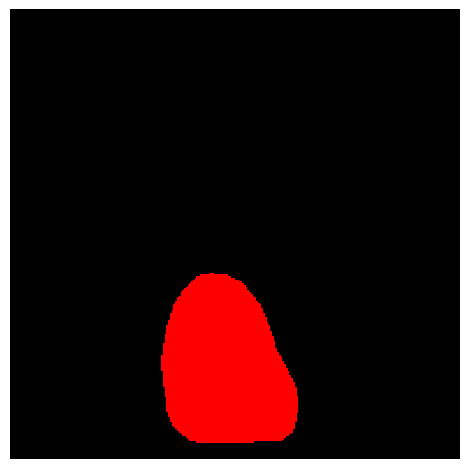

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_4 = next_step(
    supervised_3,
    supervised_steps[3],
    "Supervised - 6. Random rotate 90 degrees",
    SEED + 3,
)

ShiftScaleRotate [applied]
Supervised - 7. ShiftScaleRotate - Image


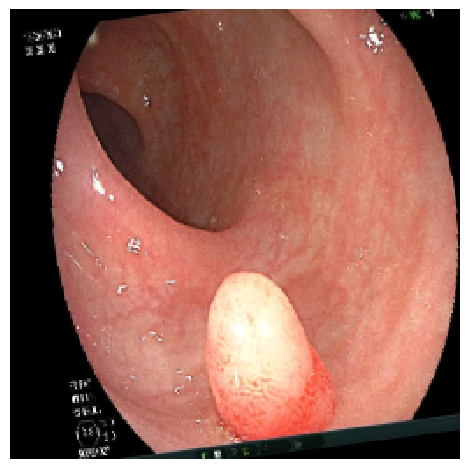

Supervised - 7. ShiftScaleRotate - Ground truth


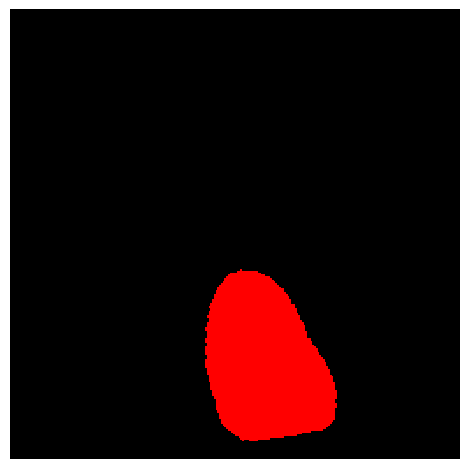

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_5 = next_step(
    supervised_4, supervised_steps[4], "Supervised - 7. ShiftScaleRotate", SEED + 4
)

OneOf -> OpticalDistortion [applied]
Supervised - 8. OneOf: elastic / grid / optical distortion - Image


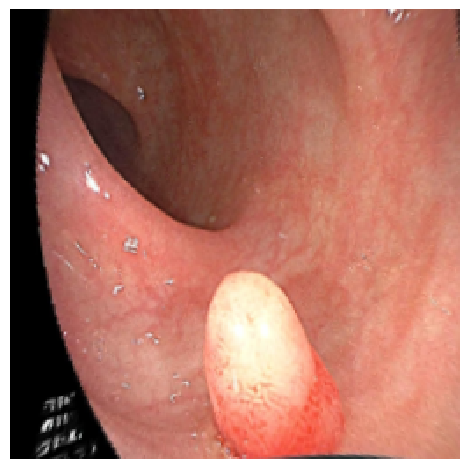

Supervised - 8. OneOf: elastic / grid / optical distortion - Ground truth


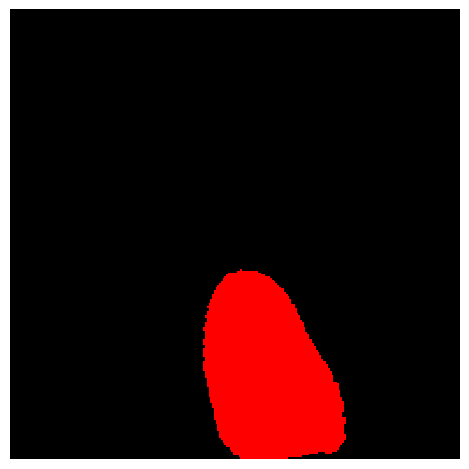

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
supervised_6 = next_step(
    supervised_5,
    supervised_steps[5],
    "Supervised - 8. OneOf: elastic / grid / optical distortion",
    SEED + 5,
)

OneOf -> RandomBrightnessContrast [applied]
Supervised - 9. OneOf: brightness-contrast / HSV - Image


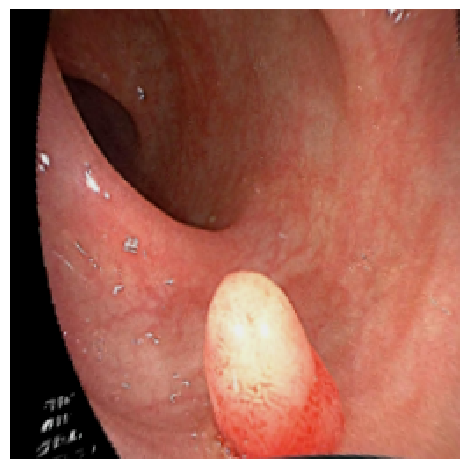

Supervised - 9. OneOf: brightness-contrast / HSV - Ground truth


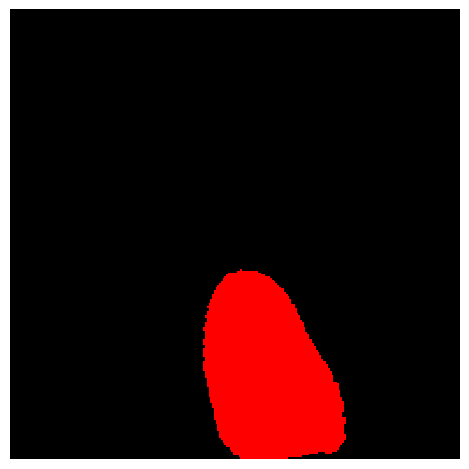

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 238.0)


In [ ]:
supervised_7 = next_step(
    supervised_6,
    supervised_steps[6],
    "Supervised - 9. OneOf: brightness-contrast / HSV",
    SEED + 6,
)

OneOf -> GaussNoise [applied]
Supervised - 10. OneOf: Gaussian noise / Gaussian blur - Image


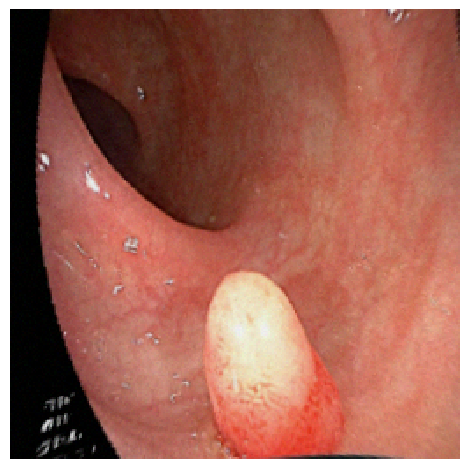

Supervised - 10. OneOf: Gaussian noise / Gaussian blur - Ground truth


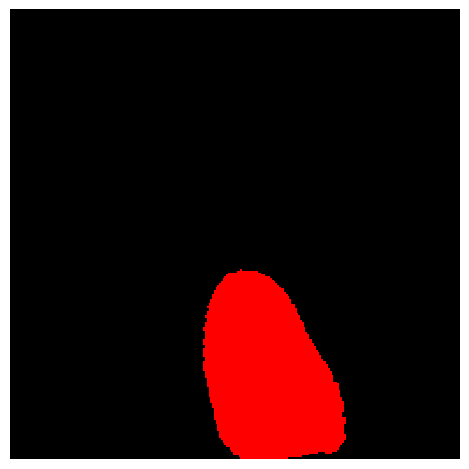

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 248.0)


In [ ]:
supervised_8 = next_step(
    supervised_7,
    supervised_steps[7],
    "Supervised - 10. OneOf: Gaussian noise / Gaussian blur",
    SEED + 7,
)

Normalize [applied]
Supervised - 11. Normalize using ImageNet mean and std - Image (inverse normalized preview)


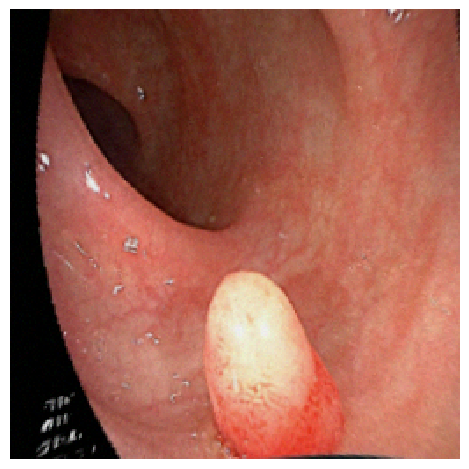

Supervised - 11. Normalize using ImageNet mean and std - Ground truth


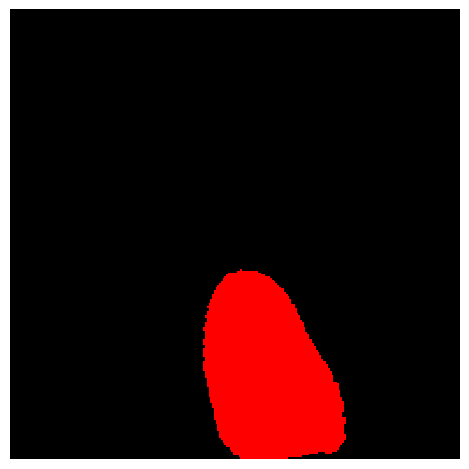

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) float32 range: (-2.1179039478302, 2.430849552154541)


In [ ]:
supervised_9 = next_step(
    supervised_8,
    supervised_steps[8],
    "Supervised - 11. Normalize using ImageNet mean and std",
    SEED + 8,
)

ToTensorV2 [applied]
Supervised - 12. ToTensor - image CHW and mask HW - Image (inverse normalized preview)


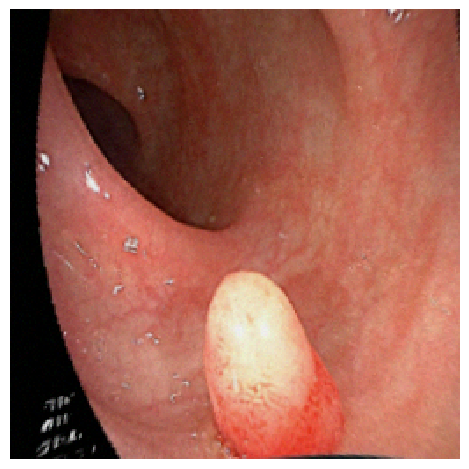

Supervised - 12. ToTensor - image CHW and mask HW - Ground truth


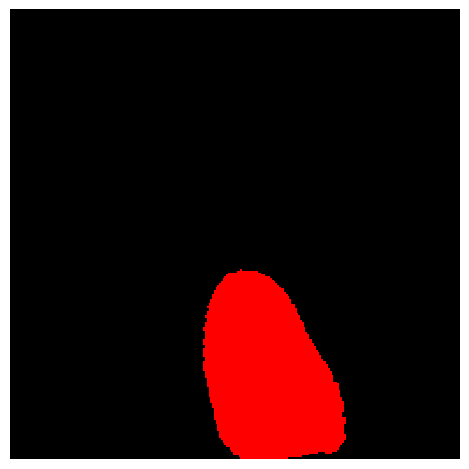

Mask: (256, 256) torch.int64 classes: [0, 2]
Image: (3, 256, 256) torch.float32 range: (-2.1179039478302, 2.430849552154541)


In [ ]:
supervised_10 = next_step(
    supervised_9,
    supervised_steps[9],
    "Supervised - 12. ToTensor - image CHW and mask HW",
    SEED + 9,
)

In [ ]:
supervised_output = supervised_10
assert supervised_output["image"].shape == (3, *IMAGE_SIZE)
assert supervised_output["mask"].shape == IMAGE_SIZE
assert supervised_output["mask"].dtype == torch.long
print("Supervised output ready")

Supervised output ready


# Student / Teacher

## Shared preprocessing and geometry

In [ ]:
labeled_geometry_steps = build_labeled_shared_geometry(
    *IMAGE_SIZE, seed=SEED
).transforms
labeled_strong_steps = build_labeled_strong_transform(seed=SEED).transforms
labeled_weak_steps = build_labeled_weak_transform(seed=SEED).transforms

Labeled - Read image and convert BGR to RGB - Image


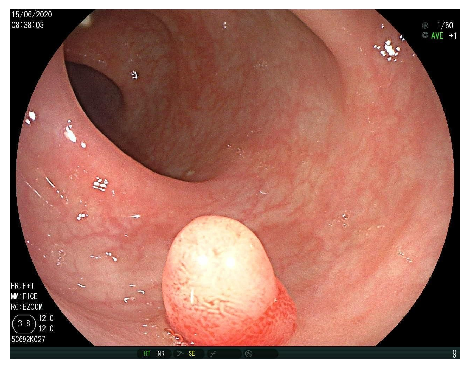

Image: (995, 1280, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_image = read_image(IMAGE_PATH, "Labeled - Read image and convert BGR to RGB")

Labeled - Read and decode ground truth - Image


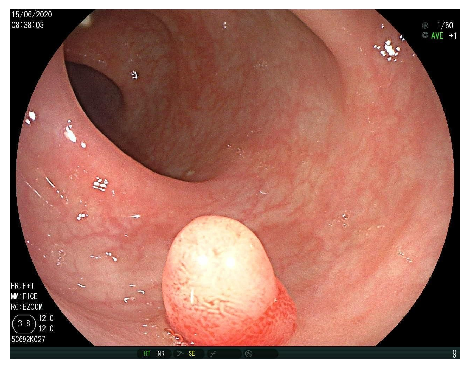

Labeled - Read and decode ground truth - Ground truth


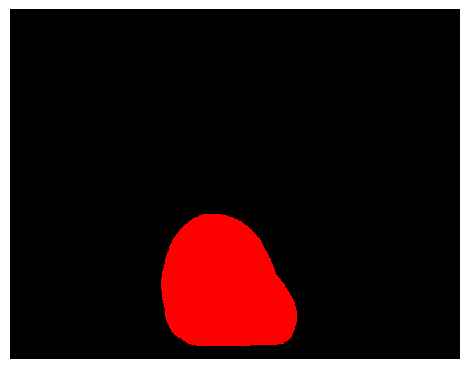

Mask: (995, 1280) uint8 classes: [0, 2]
Image: (995, 1280, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_input = add_ground_truth(
    labeled_image, GROUND_TRUTH_PATH, "Labeled - Read and decode ground truth"
)

Resize [applied]
Labeled - Shared geometry - Resize to 256 x 256 - Image


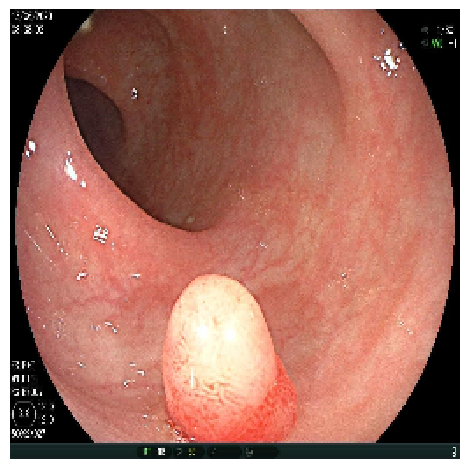

Labeled - Shared geometry - Resize to 256 x 256 - Ground truth


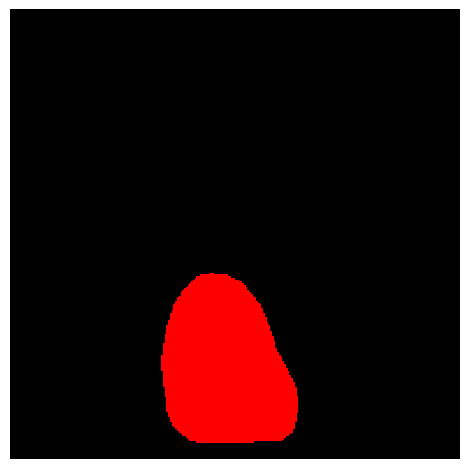

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_1 = next_step(
    labeled_input,
    labeled_geometry_steps[0],
    "Labeled - Shared geometry - Resize to 256 x 256",
    SEED + 100,
)

HorizontalFlip [applied]
Labeled - Shared geometry - Horizontal flip - Image


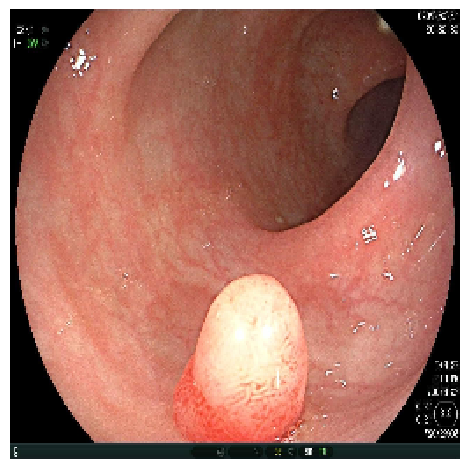

Labeled - Shared geometry - Horizontal flip - Ground truth


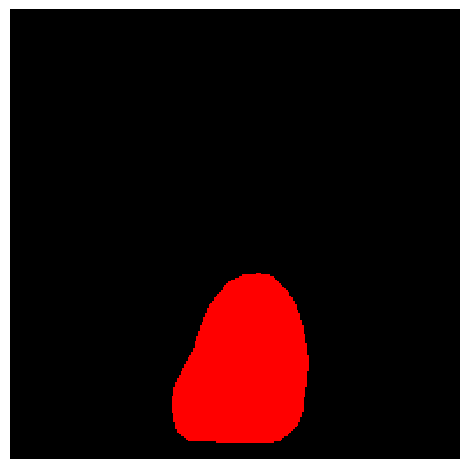

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_2 = next_step(
    labeled_geometry_1,
    labeled_geometry_steps[1],
    "Labeled - Shared geometry - Horizontal flip",
    SEED + 101,
)

VerticalFlip [applied]
Labeled - Shared geometry - Vertical flip - Image


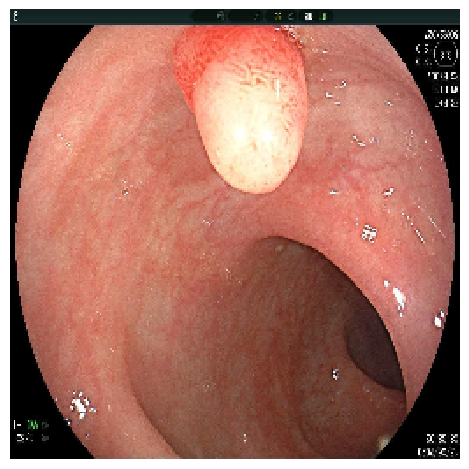

Labeled - Shared geometry - Vertical flip - Ground truth


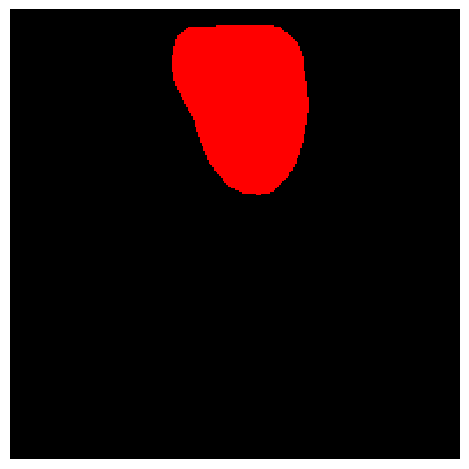

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_3 = next_step(
    labeled_geometry_2,
    labeled_geometry_steps[2],
    "Labeled - Shared geometry - Vertical flip",
    SEED + 102,
)

RandomRotate90 [applied]
Labeled - Shared geometry - Random rotate 90 degrees - Image


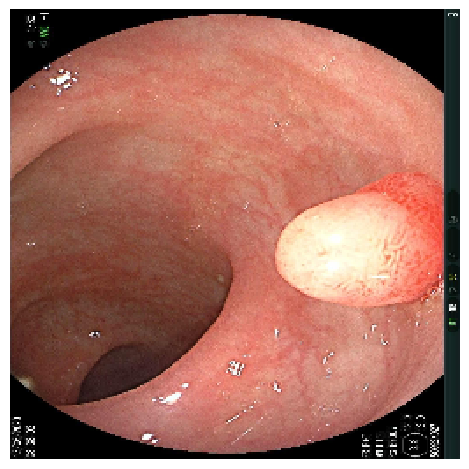

Labeled - Shared geometry - Random rotate 90 degrees - Ground truth


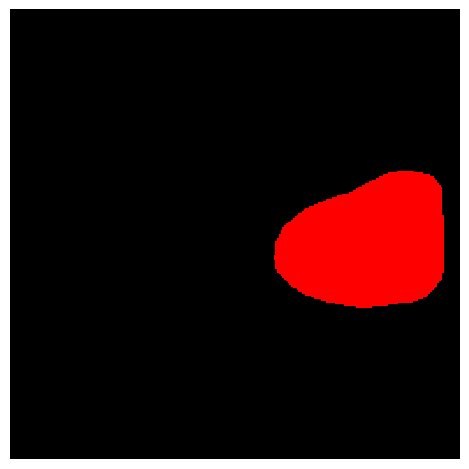

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_4 = next_step(
    labeled_geometry_3,
    labeled_geometry_steps[3],
    "Labeled - Shared geometry - Random rotate 90 degrees",
    SEED + 103,
)

Affine [applied]
Labeled - Shared geometry - Affine - translation / scale / rotation - Image


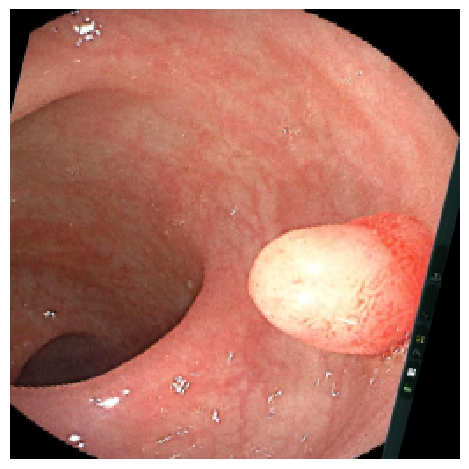

Labeled - Shared geometry - Affine - translation / scale / rotation - Ground truth


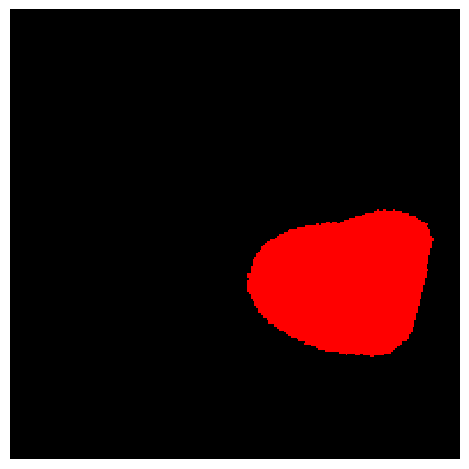

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_5 = next_step(
    labeled_geometry_4,
    labeled_geometry_steps[4],
    "Labeled - Shared geometry - Affine - translation / scale / rotation",
    SEED + 104,
)

OneOf -> OpticalDistortion [applied]
Labeled - Shared geometry - OneOf: elastic / grid / optical distortion - Image


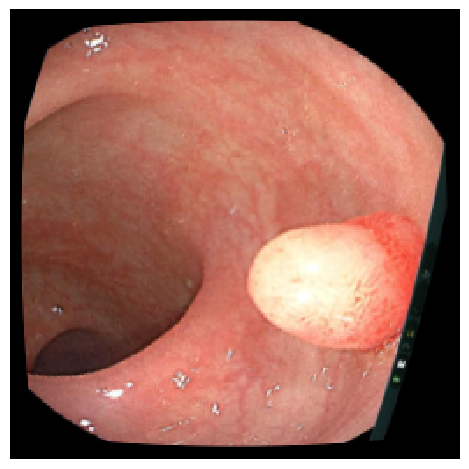

Labeled - Shared geometry - OneOf: elastic / grid / optical distortion - Ground truth


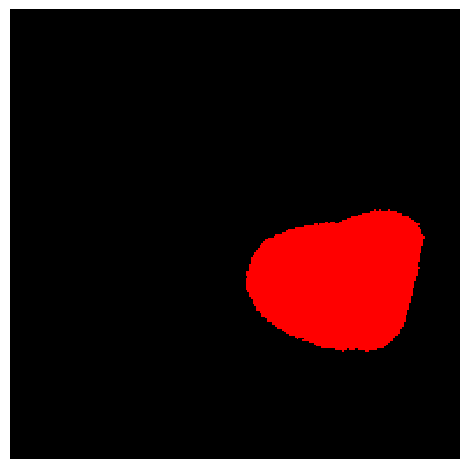

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
labeled_geometry_6 = next_step(
    labeled_geometry_5,
    labeled_geometry_steps[5],
    "Labeled - Shared geometry - OneOf: elastic / grid / optical distortion",
    SEED + 105,
)

### Labeled - Student - Strong View

OneOf -> RandomBrightnessContrast [applied]
Labeled - Strong view - OneOf: brightness-contrast / HSV - Image


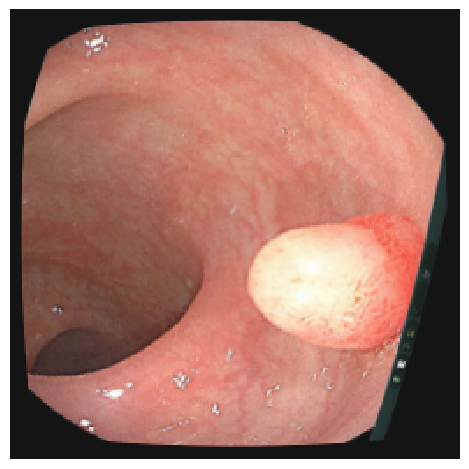

Labeled - Strong view - OneOf: brightness-contrast / HSV - Ground truth


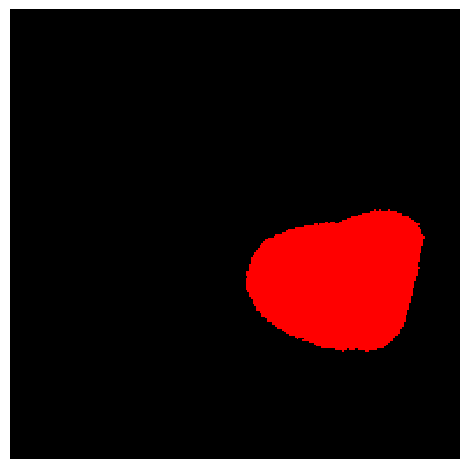

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (20.0, 252.0)


In [ ]:
labeled_strong_1 = next_step(
    labeled_geometry_6,
    labeled_strong_steps[0],
    "Labeled - Strong view - OneOf: brightness-contrast / HSV",
    SEED + 120,
)

OneOf -> GaussianBlur [applied]
Labeled - Strong view - OneOf: Gaussian noise / Gaussian blur - Image


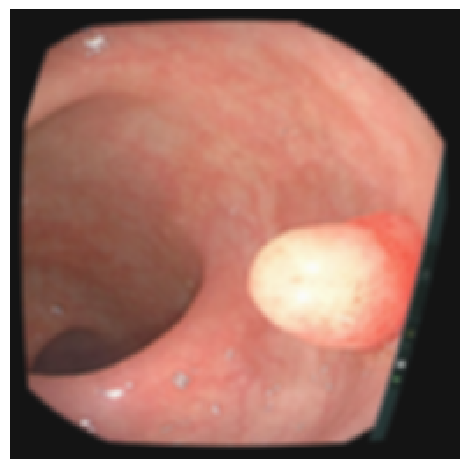

Labeled - Strong view - OneOf: Gaussian noise / Gaussian blur - Ground truth


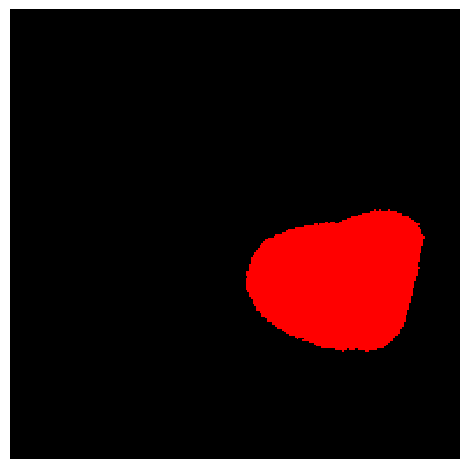

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) uint8 range: (20.0, 252.0)


In [ ]:
labeled_strong_2 = next_step(
    labeled_strong_1,
    labeled_strong_steps[1],
    "Labeled - Strong view - OneOf: Gaussian noise / Gaussian blur",
    SEED + 121,
)

Normalize [applied]
Labeled - Strong view - Normalize using ImageNet mean and std - Image (inverse normalized preview)


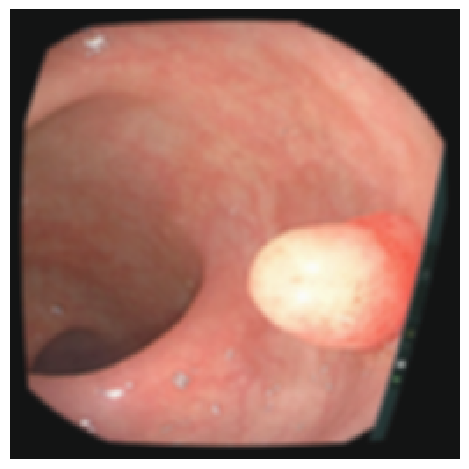

Labeled - Strong view - Normalize using ImageNet mean and std - Ground truth


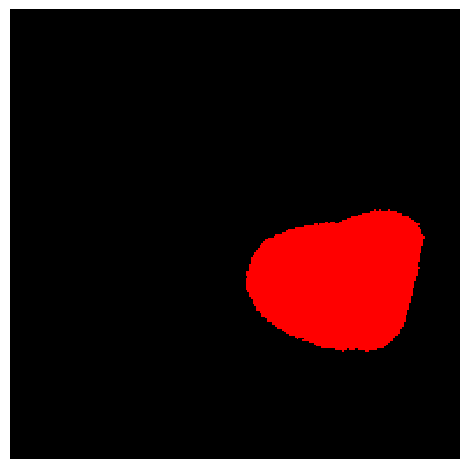

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) float32 range: (-1.7754088640213013, 2.552854061126709)


In [ ]:
labeled_strong_3 = next_step(
    labeled_strong_2,
    labeled_strong_steps[2],
    "Labeled - Strong view - Normalize using ImageNet mean and std",
    SEED + 122,
)

ToTensorV2 [applied]
Labeled - Strong view - ToTensor - CHW - Image (inverse normalized preview)


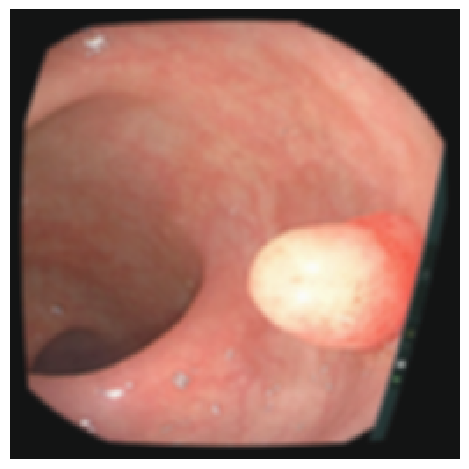

Labeled - Strong view - ToTensor - CHW - Ground truth


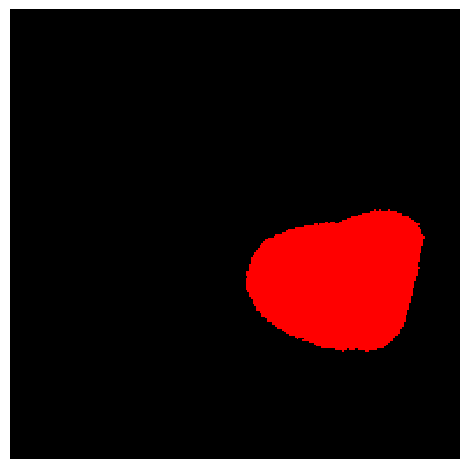

Mask: (256, 256) torch.int64 classes: [0, 2]
Image: (3, 256, 256) torch.float32 range: (-1.7754088640213013, 2.552854061126709)


In [ ]:
labeled_strong_4 = next_step(
    labeled_strong_3,
    labeled_strong_steps[3],
    "Labeled - Strong view - ToTensor - CHW",
    SEED + 123,
)

### Labeled - Teacher - Weak View

Normalize [applied]
Labeled - Weak view - Normalize using ImageNet mean and std - Image (inverse normalized preview)


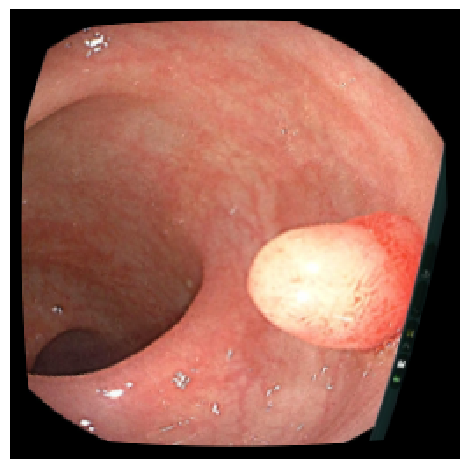

Labeled - Weak view - Normalize using ImageNet mean and std - Ground truth


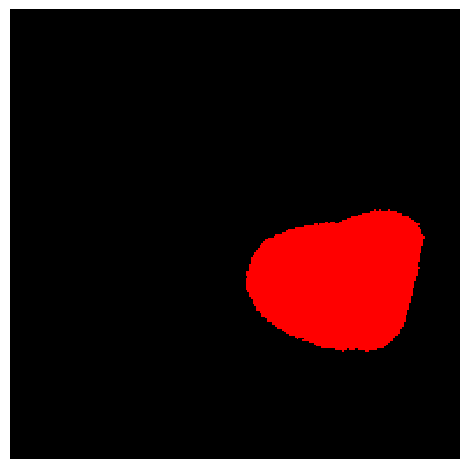

Mask: (256, 256) uint8 classes: [0, 2]
Image: (256, 256, 3) float32 range: (-2.1179039478302, 2.622570753097534)


In [ ]:
labeled_weak_1 = next_step(
    labeled_geometry_6,
    labeled_weak_steps[0],
    "Labeled - Weak view - Normalize using ImageNet mean and std",
    SEED + 130,
)

ToTensorV2 [applied]
Labeled - Weak view - ToTensor - CHW - Image (inverse normalized preview)


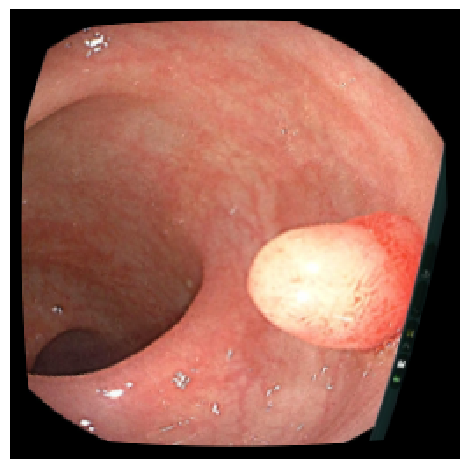

Labeled - Weak view - ToTensor - CHW - Ground truth


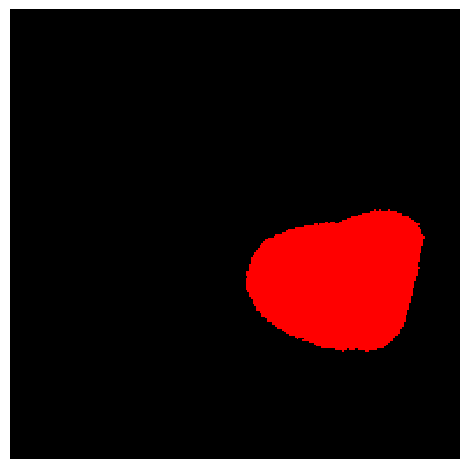

Mask: (256, 256) torch.int64 classes: [0, 2]
Image: (3, 256, 256) torch.float32 range: (-2.1179039478302, 2.622570753097534)


In [ ]:
labeled_weak_2 = next_step(
    labeled_weak_1,
    labeled_weak_steps[1],
    "Labeled - Weak view - ToTensor - CHW",
    SEED + 131,
)

In [ ]:
assert (
    labeled_strong_4["image"].shape == labeled_weak_2["image"].shape == (3, *IMAGE_SIZE)
)
assert torch.equal(labeled_strong_4["mask"], labeled_weak_2["mask"])
print("Labeled views: matching image shapes and aligned ground truth")

Labeled views: matching image shapes and aligned ground truth


## Unlabeled

### Shared preprocessing and geometry

In [ ]:
unlabeled_geometry_steps = build_unlabeled_shared_geometry(
    *IMAGE_SIZE, seed=SEED
).transforms
unlabeled_strong_steps = build_unlabeled_strong_transform(seed=SEED).transforms
unlabeled_weak_steps = build_unlabeled_weak_transform(seed=SEED).transforms

Unlabeled - Read image and convert BGR to RGB - Image


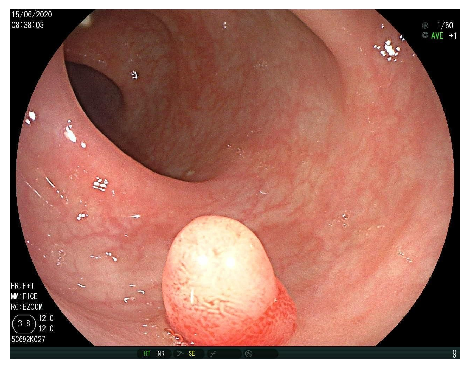

Image: (995, 1280, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_image = read_image(
    UNLABELED_IMAGE_PATH, "Unlabeled - Read image and convert BGR to RGB"
)

Resize [applied]
Unlabeled - Shared geometry - Resize to 256 x 256 - Image


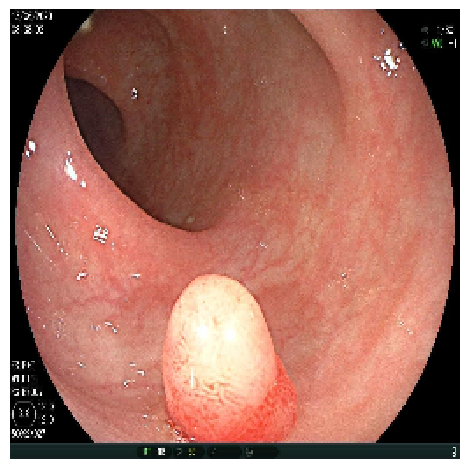

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_geometry_1 = next_step(
    unlabeled_image,
    unlabeled_geometry_steps[0],
    "Unlabeled - Shared geometry - Resize to 256 x 256",
    SEED + 200,
)

HorizontalFlip [applied]
Unlabeled - Shared geometry - Horizontal flip - Image


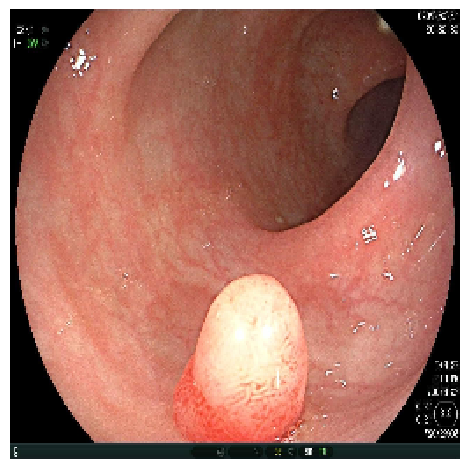

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_geometry_2 = next_step(
    unlabeled_geometry_1,
    unlabeled_geometry_steps[1],
    "Unlabeled - Shared geometry - Horizontal flip",
    SEED + 201,
)

VerticalFlip [applied]
Unlabeled - Shared geometry - Vertical flip - Image


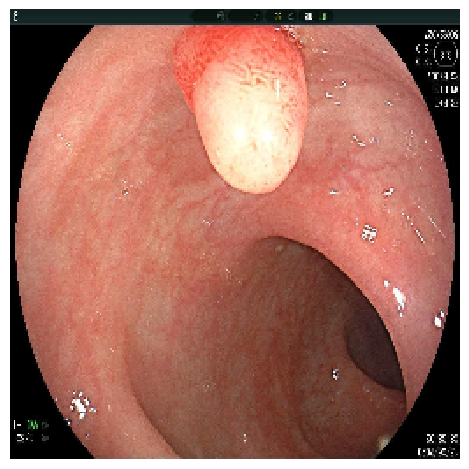

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_geometry_3 = next_step(
    unlabeled_geometry_2,
    unlabeled_geometry_steps[2],
    "Unlabeled - Shared geometry - Vertical flip",
    SEED + 202,
)

RandomRotate90 [applied]
Unlabeled - Shared geometry - Random rotate 90 degrees - Image


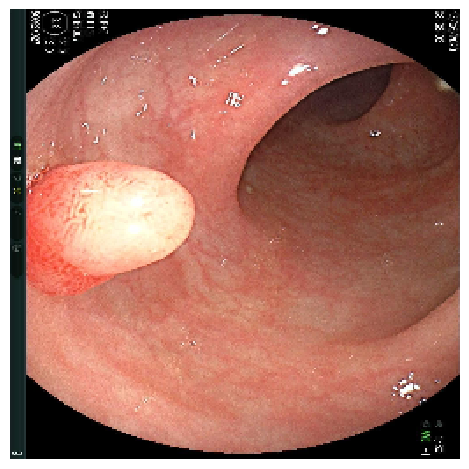

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_geometry_4 = next_step(
    unlabeled_geometry_3,
    unlabeled_geometry_steps[3],
    "Unlabeled - Shared geometry - Random rotate 90 degrees",
    SEED + 203,
)

Affine [applied]
Unlabeled - Shared geometry - Affine - translation / scale / rotation - Image


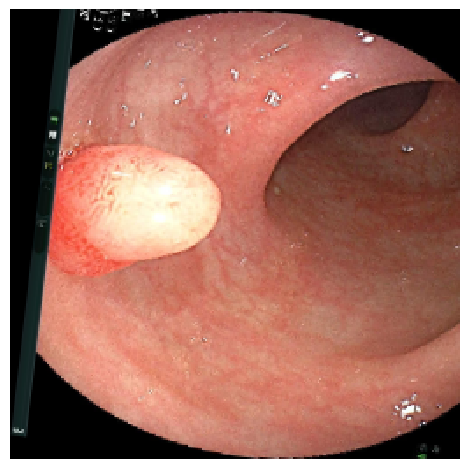

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_geometry_5 = next_step(
    unlabeled_geometry_4,
    unlabeled_geometry_steps[4],
    "Unlabeled - Shared geometry - Affine - translation / scale / rotation",
    SEED + 204,
)

### Unlabeled - Student - Strong View

OneOf -> HueSaturationValue [applied]
Unlabeled - Strong view - OneOf: brightness-contrast / HSV - Image


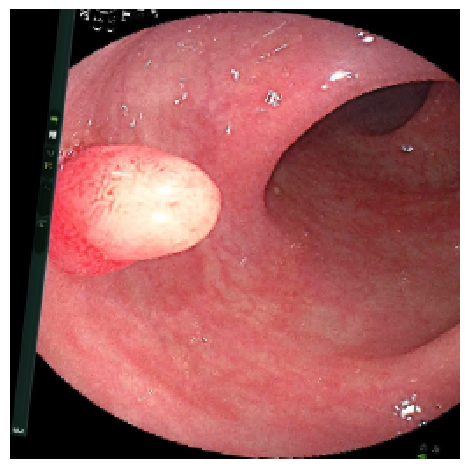

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_strong_1 = next_step(
    unlabeled_geometry_5,
    unlabeled_strong_steps[0],
    "Unlabeled - Strong view - OneOf: brightness-contrast / HSV",
    SEED + 220,
)

OneOf -> GaussNoise [applied]
Unlabeled - Strong view - OneOf: Gaussian noise / Gaussian blur - Image


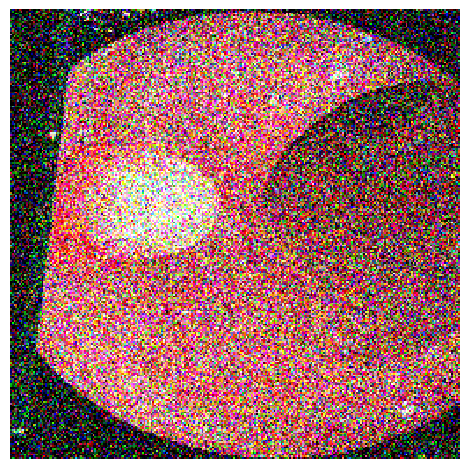

Image: (256, 256, 3) uint8 range: (0.0, 255.0)


In [ ]:
unlabeled_strong_2 = next_step(
    unlabeled_strong_1,
    unlabeled_strong_steps[1],
    "Unlabeled - Strong view - OneOf: Gaussian noise / Gaussian blur",
    SEED + 221,
)

Normalize [applied]
Unlabeled - Strong view - Normalize using ImageNet mean and std - Image (inverse normalized preview)


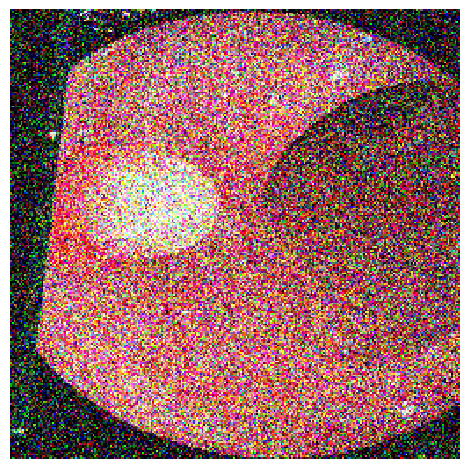

Image: (256, 256, 3) float32 range: (-2.1179039478302, 2.6399998664855957)


In [ ]:
unlabeled_strong_3 = next_step(
    unlabeled_strong_2,
    unlabeled_strong_steps[2],
    "Unlabeled - Strong view - Normalize using ImageNet mean and std",
    SEED + 222,
)

ToTensorV2 [applied]
Unlabeled - Strong view - ToTensor - CHW - Image (inverse normalized preview)


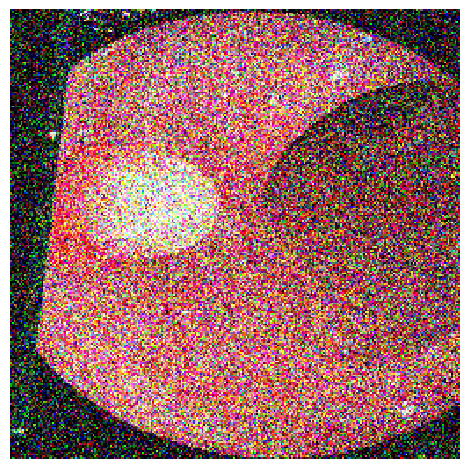

Image: (3, 256, 256) torch.float32 range: (-2.1179039478302, 2.6399998664855957)


In [ ]:
unlabeled_strong_4 = next_step(
    unlabeled_strong_3,
    unlabeled_strong_steps[3],
    "Unlabeled - Strong view - ToTensor - CHW",
    SEED + 223,
)

### Unlabeled - Teacher - Weak View

Normalize [applied]
Unlabeled - Weak view - Normalize using ImageNet mean and std - Image (inverse normalized preview)


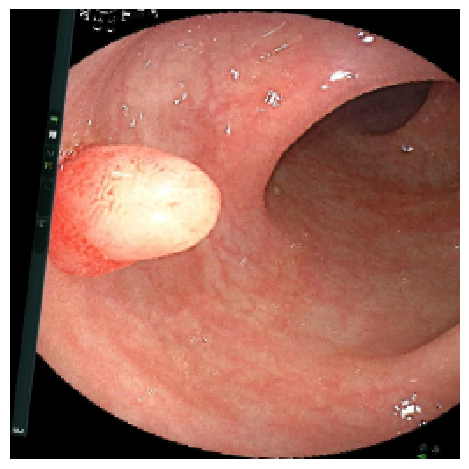

Image: (256, 256, 3) float32 range: (-2.1179039478302, 2.6399998664855957)


In [ ]:
unlabeled_weak_1 = next_step(
    unlabeled_geometry_5,
    unlabeled_weak_steps[0],
    "Unlabeled - Weak view - Normalize using ImageNet mean and std",
    SEED + 230,
)

ToTensorV2 [applied]
Unlabeled - Weak view - ToTensor - CHW - Image (inverse normalized preview)


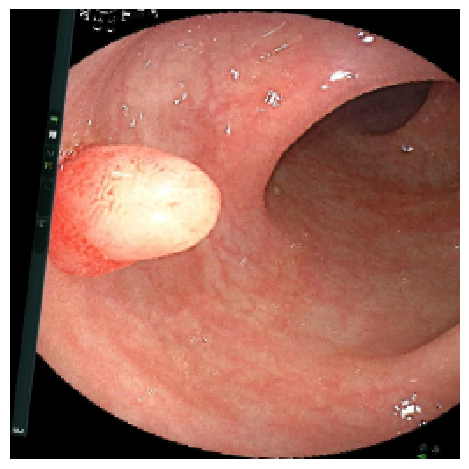

Image: (3, 256, 256) torch.float32 range: (-2.1179039478302, 2.6399998664855957)


In [ ]:
unlabeled_weak_2 = next_step(
    unlabeled_weak_1,
    unlabeled_weak_steps[1],
    "Unlabeled - Weak view - ToTensor - CHW",
    SEED + 231,
)

In [ ]:
assert (
    unlabeled_strong_4["image"].shape
    == unlabeled_weak_2["image"].shape
    == (3, *IMAGE_SIZE)
)
assert all(
    "mask" not in state
    for name, state in list(globals().items())
    if name.startswith("unlabeled_") and isinstance(state, dict)
)
print("Unlabeled views: matching image shapes; no ground truth loaded or processed")

Unlabeled views: matching image shapes; no ground truth loaded or processed
